# 02 · Keşifsel Analiz

Bu notebook, `01_cleaning.ipynb` ile üretilen `data/processed/` tablolarını kullanarak üç araştırma sorusunu yanıtlar. Grafikler `figures/` klasörüne de kaydedilir.

1. **Ev sahibi avantajı:** Seyirci ev sahibine ne kadar avantaj sağlıyor?
2. **Kadro yapısı:** Kadronun yaşı, büyüklüğü ve yabancı oranı sezon başarısıyla ilişkili mi?
3. **Gol kralları:** Gol kralı çıkaran takımlar o sezonlarda daha mı başarılı?

Kapsam 9 lig ve 2015/16–2025/26 sezonları.

**Güven aralıkları:** Grafiklerdeki %95 güven aralıkları, ortalamalar için normal yaklaşımla (ortalama ± 1,96 × standart hata), korelasyonlar için Fisher dönüşümüyle hesaplanıyor. İki yöntem de gözlemlerin birbirinden bağımsız olduğunu varsayıyor. Bu varsayım tam olarak sağlanmıyor: aynı takımın aynı sezondaki maçları birbirine benziyor, aynı takım da birçok sezonda yer alıyor. Bu yüzden aralıklar gerçekte olması gerekenden biraz dar. Bunun etkisi 1.4 ve 2.3'te, gözlemleri takım ya da takım-sezon kümeleri halinde yeniden örnekleyen bir kontrolle (küme bootstrap) ölçülüyor.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from collect import LEAGUES

PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

matches = pd.read_csv(PROCESSED / "matches.csv", parse_dates=["date"])
standings = pd.read_csv(PROCESSED / "standings.csv")
top_scorers = pd.read_csv(PROCESSED / "top_scorers.csv")
players = pd.read_csv(PROCESSED / "players.csv")
players["is_foreign"] = players["is_foreign"].astype("boolean")

LEAGUE_NAMES = {slug: info["name"] for slug, info in LEAGUES.items()}

In [2]:
# Grafik stili: sade eksenler, ince çizgiler ve en fazla üç renk.
# Renk üçlüsünün renk körlüğüne uygunluğu doğrulandı. Her grafiğin altında
# değerleri veren bir tablo da var.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.markersize": 8,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")


def mean_ci(values):
    # Ortalama ve %95 güven aralığının yarı genişliği (normal yaklaşım).
    # Gözlemlerin birbirinden bağımsız olduğunu varsayar.
    values = pd.Series(values).dropna()
    return values.mean(), 1.96 * values.std(ddof=1) / np.sqrt(len(values))


def cluster_bootstrap_ci(sums, stat, n_boot=2000, seed=0):
    # Küme bootstrap: gözlemler tek tek değil, kümeler halinde (örneğin takım-sezon)
    # yerine konarak yeniden örneklenir. Böylece aynı kümedeki gözlemlerin birbirine
    # benzemesi aralığa yansır. sums: küme başına toplamlar (satır = küme).
    # stat: toplamlardan istatistiği hesaplayan fonksiyon. %95 yüzdelik aralığı döndürür.
    rng = np.random.default_rng(seed)
    weights = rng.multinomial(len(sums), np.full(len(sums), 1 / len(sums)), size=n_boot)
    totals = pd.DataFrame(weights @ sums.to_numpy(dtype=float), columns=sums.columns)
    return np.percentile(stat(totals), [2.5, 97.5])


def season_label(season):
    return f"{season}/{str(season + 1)[-2:]}"

## Soru 1: Ev sahibi avantajı ve seyirci

**Ölçü:** Ev sahibi avantajı, bir maçta ev sahibinin aldığı puan ile deplasman takımının aldığı puan arasındaki fark (galibiyet 3, beraberlik 1 puan). Bütün maçların ortalaması, ev sahibinin maç başına puanı ile deplasman takımının maç başına puanı arasındaki farka eşit. 0, ev sahibi avantajının olmadığı anlamına geliyor.

**Dönemler:** Temizlik aşamasındaki kararla Mart 2020 – Mayıs 2022 pandemi dönemi sayılıyor.

- **Seyircisiz:** Pandemi döneminde seyirci sayısı 0 olan maçlar.
- **Pandemi, seyircili:** Pandemi döneminde kısıtlı ya da tam seyirciyle oynanan maçlar.
- **Normal dönem:** Pandemi dışında kalan ve seyirci bilgisi olan maçlar.

In [3]:
POINTS = {"H": (3, 0), "D": (1, 1), "A": (0, 3)}
matches["home_adv"] = matches["result"].map(lambda r: POINTS[r][0] - POINTS[r][1])
matches["home_win"] = matches["result"] == "H"

PANDEMIC_START = pd.Timestamp("2020-03-01", tz="UTC")
PANDEMIC_END = pd.Timestamp("2022-06-01", tz="UTC")
in_pandemic = (matches["date"] >= PANDEMIC_START) & (matches["date"] < PANDEMIC_END)
matches["period"] = np.select(
    [~in_pandemic & matches["attendance"].notna(),
     matches["attendance"] == 0,
     in_pandemic & (matches["attendance"] > 0)],
    ["Normal dönem", "Seyircisiz", "Pandemi, seyircili"],
    default="Seyirci bilgisi yok")
matches.groupby("period").agg(maç=("home_adv", "size"),
                              ev_galibiyeti=("home_win", "mean"),
                              puan_farkı=("home_adv", "mean")).round(3)

,maç,ev_galibiyeti,puan_farkı
period,,,
Normal dönem,28800,0.451,0.464
"Pandemi, seyircili",3423,0.439,0.401
Seyirci bilgisi yok,319,0.495,0.771
Seyircisiz,4100,0.405,0.207


Normal dönemde ev sahibi maçların %45,1'ini kazanıyor ve deplasman takımından maç başına ortalama 0,46 puan fazla topluyor. Seyircisiz maçlarda galibiyet oranı %40,5'e, puan farkı 0,21'e düşüyor. Yani ev sahibi avantajı yarıdan fazla (%55) azalıyor. Bu düşüşün hepsini seyirciye bağlamak zor, çünkü pandemi döneminde seyirci dışında başka koşullar da değişti: 5 oyuncu değişikliği kuralı geldi, fikstür sıkıştı, seyahat koşulları farklılaştı. Pandemi döneminde seyirciyle oynanan maçlarda fark (0,40) normal döneme yakın. Seyirci bilgisi olmayan 319 maç (çoğu Brasileirão 2016 ve 2018 sezonlarından) seyirci karşılaştırmasına alınmıyor.

### 1.1 Lig lig seyircisiz maçlar ve normal dönem

In [4]:
compare = matches[matches["period"].isin(["Normal dönem", "Seyircisiz"])]
groups = [("Tüm ligler", compare)] + [(LEAGUE_NAMES[s], g) for s, g in compare.groupby("league")]
rows = []
for name, group in groups:
    for period, sub in group.groupby("period"):
        mean, ci = mean_ci(sub["home_adv"])
        rows.append({"lig": name, "dönem": period, "maç": len(sub), "puan_farkı": mean, "ci": ci})
q1 = pd.DataFrame(rows)

q1_table = q1.pivot(index="lig", columns="dönem", values="puan_farkı")
q1_table["değişim"] = q1_table["Seyircisiz"] - q1_table["Normal dönem"]
q1_table = q1_table.loc[["Tüm ligler"] + q1_table.drop("Tüm ligler").sort_values("değişim").index.tolist()]
q1_table.round(3)

dönem,Normal dönem,Seyircisiz,değişim
lig,,,
Tüm ligler,0.464,0.207,-0.257
Ligue 1,0.446,-0.084,-0.530
Premier League,0.426,-0.014,-0.439
Eredivisie,0.470,0.086,-0.384
Brasileirão Série A,0.718,0.462,-0.256
Championship,0.420,0.179,-0.241
La Liga,0.561,0.328,-0.233
Bundesliga,0.412,0.187,-0.225
Primeira Liga,0.405,0.292,-0.113


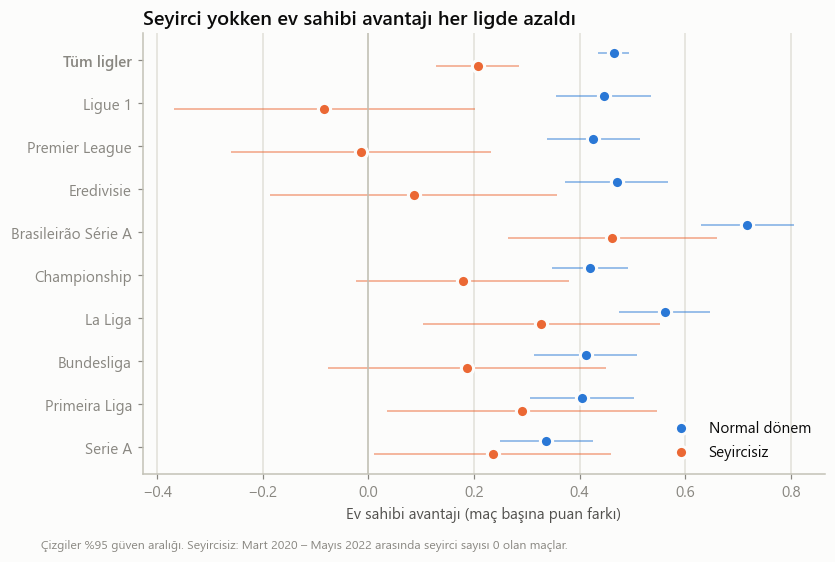

In [5]:
order = q1_table.index.tolist()[::-1]  # en üstte "Tüm ligler"
y = {name: i for i, name in enumerate(order)}
fig, ax = plt.subplots(figsize=(8, 5.2))
for offset, (period, color) in zip([0.15, -0.15], [("Normal dönem", BLUE), ("Seyircisiz", ORANGE)]):
    part = q1[q1["dönem"] == period]
    ys = part["lig"].map(y) + offset
    ax.hlines(ys, part["puan_farkı"] - part["ci"], part["puan_farkı"] + part["ci"],
              color=color, linewidth=1, alpha=0.6)
    ax.scatter(part["puan_farkı"], ys, s=64, color=color, edgecolor=SURFACE, linewidth=2,
               zorder=3, label=period)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.get_yticklabels()[-1].set_fontweight("semibold")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Ev sahibi avantajı (maç başına puan farkı)")
ax.set_title("Seyirci yokken ev sahibi avantajı her ligde azaldı")
ax.legend(loc="lower right")
fig.text(0.01, -0.02, "Çizgiler %95 güven aralığı. Seyircisiz: Mart 2020 – Mayıs 2022 arasında seyirci sayısı 0 olan maçlar.",
         color=MUTED, fontsize=8)
save(fig, "q1_seyircisiz_ev_avantaji")
plt.show()

Ev sahibi avantajı dokuz ligin hepsinde seyircisiz maçlarda düşüyor. En büyük düşüş Ligue 1, Premier League ve Eredivisie'de. Bu üç ligde seyircisiz maçlarda avantaj neredeyse tamamen ortadan kalkıyor. Serie A ve Primeira Liga'da düşüş küçük ve güven aralıkları örtüşüyor. Lig başına seyircisiz maç sayısı 322 ile 638 arasında olduğundan tek tek ligler için kesin konuşmak zor. Tüm ligler birlikte ele alındığında ise düşüş net, iki dönemin güven aralıkları örtüşmüyor. Brasileirão'da ev sahibi avantajı (0,72) diğer liglerin belirgin biçimde üstünde; seyircisiz maçlarda bile (0,46) diğer liglerin normal dönem seviyesinde kalıyor.

### 1.2 Seyirci azaldıkça avantaj nasıl değişiyor?

Pandemi döneminde birçok maç kısıtlı seyirciyle oynandı. Burada her maçtaki seyirci, ev sahibinin pandemi dışındaki ortanca (medyan) seyircisine oranlanıyor. Böylece stadyum büyüklüğünden bağımsız bir doluluk ölçüsü elde ediliyor. Pandemi dışında hiç maçı olmayan takımlar bu karşılaştırmaya giremiyor.

In [6]:
baseline = matches[~in_pandemic & matches["attendance"].notna()].groupby("home_team_id")["attendance"].median()
matches["occupancy"] = matches["attendance"] / matches["home_team_id"].map(baseline)
pandemic = matches[in_pandemic & matches["occupancy"].notna()].copy()

OCCUPANCY_LABELS = ["Seyircisiz", "%25'e kadar", "%25–50", "%50–75", "%75 ve üstü"]
pandemic["doluluk"] = pd.cut(pandemic["occupancy"], bins=[-np.inf, 0, 0.25, 0.5, 0.75, np.inf],
                             labels=OCCUPANCY_LABELS)
dose = pandemic.groupby("doluluk", observed=True)["home_adv"].agg(maç="size", puan_farkı="mean", sd="std")
dose["ci"] = 1.96 * dose.pop("sd") / np.sqrt(dose["maç"])
normal_mean = q1_table.loc["Tüm ligler", "Normal dönem"]
dose.round(3)

,maç,puan_farkı,ci
doluluk,,,
Seyircisiz,4059,0.212,0.079
%25'e kadar,300,0.500,0.292
%25–50,442,0.577,0.238
%50–75,640,0.530,0.193
%75 ve üstü,1985,0.342,0.113


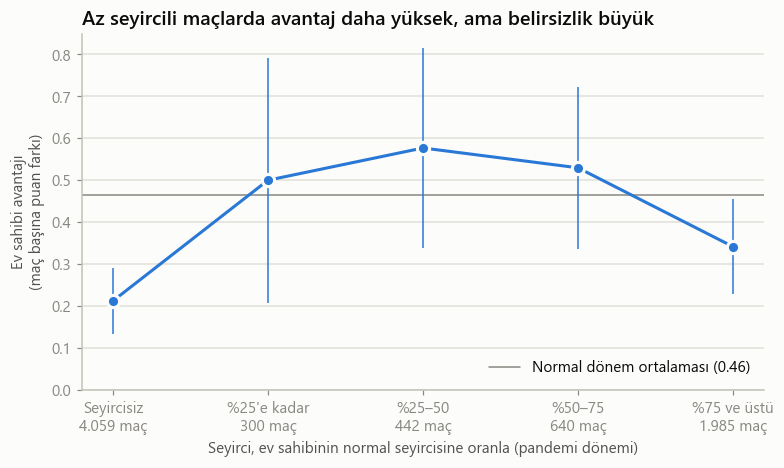

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(dose))
ax.axhline(normal_mean, color=MUTED, linewidth=1, label=f"Normal dönem ortalaması ({normal_mean:.2f})")
ax.errorbar(x, dose["puan_farkı"], yerr=dose["ci"], color=BLUE, ecolor=BLUE, elinewidth=1,
            capsize=0, marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xticks(x, [f"{label}\n{n:,} maç".replace(",", ".") for label, n in zip(dose.index, dose["maç"])])
ax.legend(loc="lower right")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Seyirci, ev sahibinin normal seyircisine oranla (pandemi dönemi)")
ax.set_ylabel("Ev sahibi avantajı\n(maç başına puan farkı)")
ax.set_title("Az seyircili maçlarda avantaj daha yüksek, ama belirsizlik büyük")
save(fig, "q1_doluluk_ev_avantaji")
plt.show()

Seyircisiz maçlarda avantaj 0,21. En kısıtlı seyirciyle (normal seyircinin %25'ine kadar) oynanan maçlarda ise 0,50 ve normal dönem ortalamasına (0,46) yakın. Bu, seyircinin sayısından çok stadyumda bulunup bulunmamasının önemli olabileceğini düşündürüyor. Ancak bu veride görülen bir eğilim, kesin bir sonuç değil. Kısıtlı seyirci gruplarında 300 ile 640 arasında maç var ve güven aralıkları çok geniş: %25'e kadar grubunun aralığı (0,21–0,79) seyircisiz maçların ortalamasına kadar uzanıyor. Bu konuda bir sonuca varmak için daha fazla veri ve ayrıntılı inceleme gerekiyor.

Doluluğun %75'i aştığı maçlarda avantajın normal dönemin altında kalması (0,34) ise kısmen bir dönem etkisi. Bu maçların %93'ü 2021/22 sezonundan ve pandemi sonrası dönemde ev sahibi avantajı genel olarak daha düşük (0,42; bkz. 1.3). Güven aralığı (0,23–0,45) bu seviyeyi de içeriyor.

### 1.3 Zaman içinde ev sahibi avantajı

Seyircisiz maçlardaki düşüş, zaten süregelen bir düşüş eğiliminin parçası olabilir. Bunu kontrol etmek için sezonlara göre bakılıyor. Pandemi dönemindeki seyircili maçlar bu grafikte gösterilmiyor, çünkü bu grubun lig bileşimi sezondan sezona çok değişiyor. Örneğin 2022 noktası yalnızca Brasileirão maçlarından oluşuyor ve Brasileirão'da ev sahibi avantajı zaten çok yüksek.

In [8]:
trend = (matches[matches["period"].isin(["Normal dönem", "Seyircisiz"])]
         .groupby(["season", "period"])["home_adv"].agg(["mean", "size"]).reset_index())
trend = trend[trend["size"] >= 30]  # çok az maçlı sezon-dönem noktaları gürültülü
trend.pivot(index="season", columns="period", values="mean").round(3)

period,Normal dönem,Seyircisiz
season,,
2015,0.470,NaN
2016,0.600,NaN
2017,0.462,NaN
2018,0.527,NaN
2019,0.461,0.195
2020,NaN,0.212
2021,NaN,0.183
2022,0.440,NaN
2023,0.398,NaN


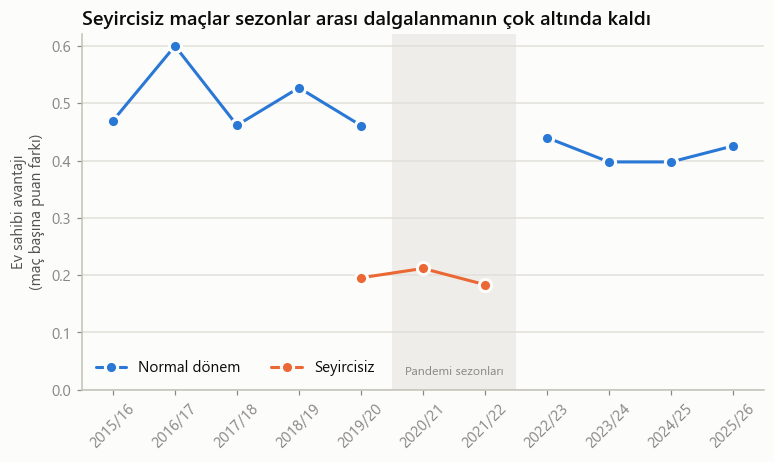

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for period, color in [("Normal dönem", BLUE), ("Seyircisiz", ORANGE)]:
    part = trend[trend["period"] == period].set_index("season").reindex(range(2015, 2026))
    ax.plot(part.index, part["mean"], color=color, marker="o", markeredgecolor=SURFACE,
            markeredgewidth=2, label=period)
ax.axvspan(2019.5, 2021.5, color=GRID, alpha=0.5, linewidth=0)
ax.set_xticks(range(2015, 2026), [season_label(s) for s in range(2015, 2026)], rotation=45)
ax.set_ylim(0, None)
ax.text(2020.5, 0.02, "Pandemi sezonları", ha="center", va="bottom", color=MUTED, fontsize=8)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Ev sahibi avantajı\n(maç başına puan farkı)")
ax.set_title("Seyircisiz maçlar sezonlar arası dalgalanmanın çok altında kaldı")
ax.legend(loc="lower left", ncols=2)
save(fig, "q1_sezonlara_gore_ev_avantaji")
plt.show()

Normal dönemde ev sahibi avantajı sezondan sezona 0,40 ile 0,60 arasında dalgalanıyor. Seyircisiz maçlar (0,18–0,21) bu aralığın çok altında kalıyor. Dolayısıyla düşüş, genel bir eğilimle açıklanamıyor. Öte yandan pandemi sonrası sezonlarda (2022/23–2025/26, ortalama 0,42) avantaj, pandemi öncesine (2015/16–2018/19, ortalama 0,51) göre biraz daha düşük. Seyirciler dönse de avantaj eski seviyesine tam olarak çıkmamış görünüyor.

### 1.4 Güven aralıkları ne kadar güvenilir?

Yukarıdaki aralıklar her maçı bağımsız sayıyor. Oysa aynı ev sahibi takımın aynı sezondaki maçları birbirine benziyor (takımın gücü, stadyumu, o sezonki formu). Burada aynı ev sahibi takımın bir sezondaki maçları tek bir küme sayılıyor ve kümeler yeniden örnekleniyor. "Azalma" satırı, seyircisiz maçlarda avantajın normal döneme göre yüzde kaç düştüğünü gösteriyor.

In [10]:
home_season = ["home_team_id", "season"]
is_normal = compare["period"] == "Normal dönem"
is_empty = compare["period"] == "Seyircisiz"
sums = compare.assign(
    adv_normal=compare["home_adv"].where(is_normal, 0), n_normal=is_normal,
    adv_empty=compare["home_adv"].where(is_empty, 0), n_empty=is_empty,
).groupby(home_season)[["adv_normal", "n_normal", "adv_empty", "n_empty"]].sum()

estimates = {
    "Normal dönem": lambda t: t["adv_normal"] / t["n_normal"],
    "Seyircisiz": lambda t: t["adv_empty"] / t["n_empty"],
    "Azalma (%)": lambda t: 100 * (1 - (t["adv_empty"] / t["n_empty"]) / (t["adv_normal"] / t["n_normal"])),
}
naive = q1[q1["lig"] == "Tüm ligler"].set_index("dönem")
rows = []
for name, stat in estimates.items():
    low, high = cluster_bootstrap_ci(sums, stat)
    mean, ci = naive.loc[name, ["puan_farkı", "ci"]] if name in naive.index else (np.nan, np.nan)
    rows.append({"ölçü": name, "değer": stat(sums.sum()), "bağımsız_alt": mean - ci,
                 "bağımsız_üst": mean + ci, "küme_alt": low, "küme_üst": high})
for label, group in pandemic.groupby("doluluk", observed=True):
    per_cluster = group.groupby(home_season)["home_adv"].agg(adv="sum", n="size")
    low, high = cluster_bootstrap_ci(per_cluster, lambda t: t["adv"] / t["n"])
    mean, ci = dose.loc[label, ["puan_farkı", "ci"]]
    rows.append({"ölçü": f"Doluluk: {label}", "değer": mean, "bağımsız_alt": mean - ci,
                 "bağımsız_üst": mean + ci, "küme_alt": low, "küme_üst": high})
q1_ci = pd.DataFrame(rows).set_index("ölçü")
q1_ci["genişleme"] = (q1_ci["küme_üst"] - q1_ci["küme_alt"]) / (q1_ci["bağımsız_üst"] - q1_ci["bağımsız_alt"])
q1_ci.round(2)

,değer,bağımsız_alt,bağımsız_üst,küme_alt,küme_üst,genişleme
ölçü,,,,,,
Normal dönem,0.46,0.43,0.49,0.42,0.51,1.61
Seyircisiz,0.21,0.13,0.29,0.09,0.32,1.47
Azalma (%),55.42,NaN,NaN,30.30,81.14,NaN
Doluluk: Seyircisiz,0.21,0.13,0.29,0.09,0.33,1.51
Doluluk: %25'e kadar,0.50,0.21,0.79,0.17,0.83,1.14
Doluluk: %25–50,0.58,0.34,0.81,0.33,0.86,1.11
Doluluk: %50–75,0.53,0.34,0.72,0.30,0.75,1.16
Doluluk: %75 ve üstü,0.34,0.23,0.45,0.19,0.49,1.36


Küme bootstrap aralıkları, maçları bağımsız sayan aralıklardan 1,1–1,6 kat daha geniş. Ana sonuç değişmiyor: normal dönemin alt sınırı (0,42) seyircisiz maçların üst sınırının (0,32) üstünde kalıyor. Ancak düşüşün büyüklüğü belirsiz: %55'lik azalmanın aralığı yaklaşık %30 ile %81 arasında. Doluluk gruplarında aralıklar daha da geniş; %25'e kadar grubunun aralığı (0,17–0,83) hem seyircisiz maçların hem de normal dönemin ortalamasını içeriyor.

**Soru 1 için yanıt:** Seyircisiz oynanan 4.100 maçta ev sahibinin puan avantajı normal döneme göre yarıdan fazla azaldı (0,46'dan 0,21'e) ve bu düşüş dokuz ligin hepsinde görüldü. Bu, seyircinin ev sahibi avantajında önemli bir rol oynadığına işaret ediyor. Ancak düşüşün tamamı seyirciye bağlanamaz, çünkü pandemi döneminde 5 oyuncu değişikliği kuralı, sıkışık fikstür ve farklı seyahat koşulları gibi başka koşullar da değişti. Avantajın tamamı da kaybolmadı; seyirci olmadan da ev sahibi, deplasman takımından daha çok puan topladı. Kalan bu kısım, saha alışkanlığı ve deplasman yolculuğu gibi seyirciden bağımsız etkenlerden kaynaklanıyor olabilir. Az seyirciyle oynanan maçlarda avantajın normal seviyeye yaklaşması ilginç bir eğilim, ama güven aralıkları bunun üzerine kesin bir yorum yapmaya izin vermiyor.

## Soru 2: Kadro yapısı ve sezon başarısı

**Kadro tanımı:** Temizlikte onaylanan tanım kullanılıyor. Kadro, o sezon en az 1 lig maçına çıkan oyunculardan oluşuyor. Maç sayısı verisi eksik takım-sezonlar (`team_complete = False`) analize alınmıyor.

**Takım düzeyinde ölçüler:**

- **Kadro büyüklüğü:** O sezon kullanılan oyuncu sayısı.
- **Ortalama yaş:** Oyuncuların sezon ortasındaki yaşlarının ortalaması. Maç sayısıyla ağırlıklı ortalama da ek kontrol olarak hesaplanıyor.
- **Yabancı oranı:** Uyruğu bilinen oyuncular arasında yabancıların payı.

**Başarı ölçüsü:** Maç başına puan.

Ligler arasında büyük yapısal farklar var; örneğin Brezilya takımları çok daha fazla oyuncu kullanıyor. Bu yüzden her ölçü, takımın kendi lig-sezonundaki diğer takımlarla karşılaştırılıyor.

In [11]:
squad = players[players["team_complete"] & (players["appearances"] >= 1)].copy()
squad["age_x_apps"] = squad["age"] * squad["appearances"]
squad["apps_with_age"] = squad["appearances"].where(squad["age"].notna())
team = squad.groupby(["league", "season", "team_id"]).agg(
    squad_size=("player_id", "size"),
    mean_age=("age", "mean"),
    age_x_apps=("age_x_apps", "sum"),
    apps_with_age=("apps_with_age", "sum"),
    foreign_share=("is_foreign", "mean"),
)
team["weighted_age"] = team.pop("age_x_apps") / team.pop("apps_with_age")
team = team.join(standings.set_index(["league", "season", "team_id"])[["team", "points", "played", "rank"]])
team["ppg"] = team["points"] / team["played"]
print(team.shape, "takım-sezon")
team.describe().round(2)

(1730, 9) takım-sezon


,squad_size,mean_age,foreign_share,weighted_age,points,played,rank,ppg
count,1730.00,1730.00,1730.0,1730.00,1730.00,1730.00,1730.00,1730.00
mean,26.38,25.87,0.49,26.50,51.69,37.61,10.41,1.38
std,3.60,1.29,0.2,1.30,17.35,3.89,5.83,0.45
min,17.00,21.74,0.0,21.39,0.00,27.00,1.00,0.00
25%,24.00,25.03,0.36,25.69,39.00,34.00,5.00,1.08
50%,26.00,25.85,0.52,26.53,49.00,38.00,10.00,1.29
75%,28.00,26.72,0.63,27.33,63.00,38.00,15.00,1.63
max,48.00,29.92,0.95,31.31,101.00,46.00,24.00,2.68


### 2.1 Lig içinde ilişkinin gücü

Her ölçü ve maç başına puan, lig-sezon içinde standartlaştırılıyor (z-puanı). Böylece ligler ve sezonlar arasındaki farklar ayıklanıyor. Ardından her lig için korelasyon (r) hesaplanıyor. r'nin pozitif olması, o ölçüde yüksek olan takımların daha çok puan topladığı anlamına geliyor.

In [12]:
METRICS = {"mean_age": "Ortalama yaş", "weighted_age": "Ağırlıklı ortalama yaş",
           "squad_size": "Kadro büyüklüğü", "foreign_share": "Yabancı oranı"}
cols = list(METRICS) + ["ppg"]
by_season = team.groupby(["league", "season"])[cols]
z = (team[cols] - by_season.transform("mean")) / by_season.transform("std")

rows = []
groups = [("Tüm ligler", z)] + [(LEAGUE_NAMES[s], g) for s, g in z.groupby("league")]
for name, group in groups:
    for metric, label in METRICS.items():
        pair = group[[metric, "ppg"]].dropna()
        r = pair[metric].corr(pair["ppg"])
        half = 1.96 / np.sqrt(len(pair) - 3)  # Fisher dönüşümüyle %95 güven aralığı
        rows.append({"lig": name, "ölçü": label, "r": r, "n": len(pair),
                     "alt": np.tanh(np.arctanh(r) - half), "üst": np.tanh(np.arctanh(r) + half)})
q2 = pd.DataFrame(rows)
q2_table = q2.pivot(index="lig", columns="ölçü", values="r")[list(METRICS.values())]
q2_table = q2_table.loc[["Tüm ligler"] + [n for n in LEAGUE_NAMES.values()]]
q2_table.round(2)

ölçü,Ortalama yaş,Ağırlıklı ortalama yaş,Kadro büyüklüğü,Yabancı oranı
lig,,,,
Tüm ligler,-0.06,-0.05,-0.18,0.19
Premier League,-0.19,-0.13,-0.24,0.24
Championship,0.13,0.05,-0.29,0.26
Bundesliga,-0.06,-0.05,-0.20,0.19
La Liga,-0.11,-0.04,-0.15,0.27
Serie A,0.28,0.17,-0.38,0.30
Ligue 1,-0.18,-0.19,-0.19,0.17
Eredivisie,-0.22,-0.14,0.02,0.07
Primeira Liga,-0.26,-0.18,0.04,-0.17


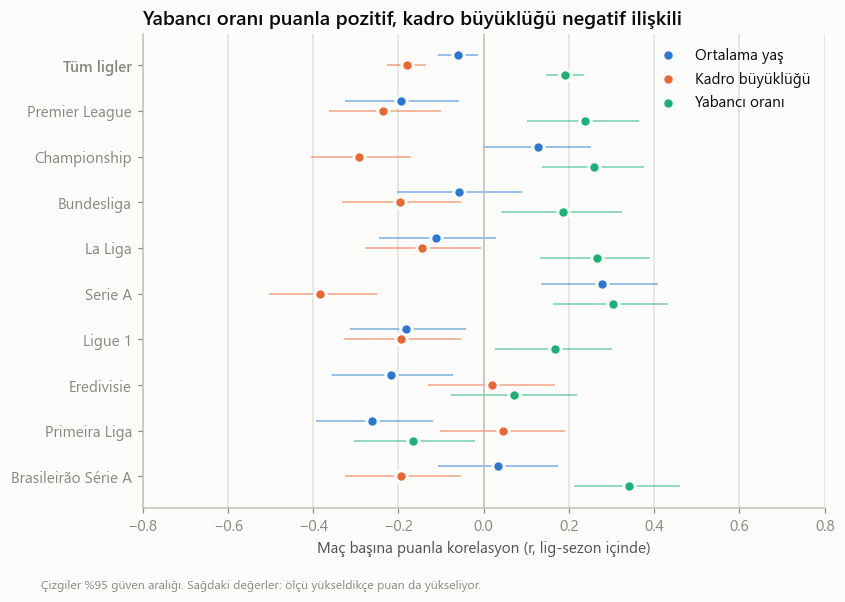

In [13]:
plotted = [("Ortalama yaş", BLUE), ("Kadro büyüklüğü", ORANGE), ("Yabancı oranı", AQUA)]
order = q2_table.index.tolist()[::-1]
y = {name: i for i, name in enumerate(order)}
fig, ax = plt.subplots(figsize=(8, 5.6))
for offset, (label, color) in zip([0.22, 0, -0.22], plotted):
    part = q2[q2["ölçü"] == label]
    ys = part["lig"].map(y) + offset
    ax.hlines(ys, part["alt"], part["üst"], color=color, linewidth=1, alpha=0.6)
    ax.scatter(part["r"], ys, s=56, color=color, edgecolor=SURFACE, linewidth=2, zorder=3, label=label)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.get_yticklabels()[-1].set_fontweight("semibold")
ax.grid(axis="y", visible=False)
ax.set_xlim(-0.8, 0.8)
ax.set_xlabel("Maç başına puanla korelasyon (r, lig-sezon içinde)")
ax.set_title("Yabancı oranı puanla pozitif, kadro büyüklüğü negatif ilişkili")
ax.legend(loc="upper right")
fig.text(0.01, -0.02, "Çizgiler %95 güven aralığı. Sağdaki değerler: ölçü yükseldikçe puan da yükseliyor.",
         color=MUTED, fontsize=8)
save(fig, "q2_kadro_korelasyon")
plt.show()

- **Yabancı oranı:** 9 ligin 8'inde pozitif ilişki var (tüm ligler r = 0,19; Eredivisie'de zayıf). Yani yabancı oranı yüksek takımlar daha çok puan topluyor. İstisna Primeira Liga (r = −0,17). Portekiz'de yabancı oranı ilk üç takımda (%58) diğer takımlardan (%61) bile düşük, yabancı oyuncular lig geneline yayılmış durumda.
- **Kadro büyüklüğü:** 7 ligde negatif ilişki var (tüm ligler r = −0,18); daha çok oyuncu kullanan takımlar daha az puan topluyor. Ancak bu ilişki ters yönlü olabilir. Kötü giden takımlar teknik direktör değiştiriyor, yeni oyuncular deniyor ve devre arasında transfer yapıyor. Yani çok oyuncu kullanmak başarısızlığın nedeni değil, sonucu olabilir.
- **Ortalama yaş:** Tutarlı bir ilişki yok (tüm ligler r = −0,06). Serie A'da yaşlı kadrolar daha başarılı (r = 0,28). Primeira Liga, Eredivisie ve Premier League'de ise genç kadrolar daha başarılı. Maç sayısıyla ağırlıklı yaş da aynı tabloyu veriyor (r = −0,05).

### 2.2 Dilimlere göre maç başına puan

Korelasyon yalnızca doğrusal ilişkiyi ölçüyor. İlişkinin şeklini görmek için her lig-sezondaki takımlar, her ölçüye göre beş dilime ayrılıyor. Ardından her dilimin ortalama maç başına puanı hesaplanıyor.

**Eşit değerler:** Kadro büyüklüğü bir tam sayı olduğu için aynı lig-sezonda aynı sayıda oyuncu kullanan çok sayıda takım var. Eşitlikleri satır sırasına göre bozmak (`rank(method="first")`) aynı değerdeki takımları keyfi olarak farklı dilimlere ayırır. Üstelik satırlar ESPN takım id'sine göre sıralı olduğu için bu sıra rastgele de değil. Bu yüzden takımlar ortalama sıralarına göre dilimlere ayrılıyor ve aynı değerdeki takımlar hep aynı dilime düşüyor. Bunun bedeli, dilimlerin tam eşit büyüklükte olmaması. Aşağıdaki ilk tabloda iki yöntem karşılaştırılıyor.

In [14]:
PANELS = [("mean_age", "Ortalama yaş", ("En genç", "En yaşlı")),
          ("squad_size", "Kadro büyüklüğü", ("En az\noyuncu", "En çok\noyuncu")),
          ("foreign_share", "Yabancı oranı", ("En az\nyabancı", "En çok\nyabancı"))]


def quintile(values, ties="average"):
    # Lig-sezon içinde 1-5 arası dilim. ties="average": eşit değerler aynı dilime düşer.
    # ties="first": eşitlikler satır sırasına göre bozulur (yalnızca karşılaştırma için).
    return np.ceil(values.rank(method=ties) * 5 / values.count())


quintiles, tie_check = {}, {}
for metric, label, _ in PANELS:
    by_season = team.groupby(["league", "season"])[metric]
    bucket = by_season.transform(quintile)
    bucket_first = by_season.transform(quintile, ties="first")
    team[f"{metric}_q"] = bucket
    stats = team.groupby(bucket)["ppg"].agg(ortalama="mean", sd="std", n="size")
    stats["ci"] = 1.96 * stats.pop("sd") / np.sqrt(stats["n"])
    stats.index = stats.index.astype(int)
    quintiles[label] = stats
    by_first = team.groupby(bucket_first)["ppg"].mean()
    tie_check[label] = {"dilimi değişen takım (%)": 100 * (bucket != bucket_first)[bucket.notna()].mean(),
                        "en düşük dilim: eşitler birlikte": stats["ortalama"].iloc[0],
                        "en düşük dilim: sıraya göre": by_first.iloc[0],
                        "en yüksek dilim: eşitler birlikte": stats["ortalama"].iloc[-1],
                        "en yüksek dilim: sıraya göre": by_first.iloc[-1]}
display(pd.DataFrame(tie_check).T.round(2))
pd.concat({label: s["ortalama"] for label, s in quintiles.items()}, axis=1).round(2).rename_axis("dilim")

,dilimi değişen takım (%),en düşük dilim: eşitler birlikte,en düşük dilim: sıraya göre,en yüksek dilim: eşitler birlikte,en yüksek dilim: sıraya göre
Ortalama yaş,0.00,1.41,1.41,1.32,1.32
Kadro büyüklüğü,15.78,1.48,1.50,1.26,1.24
Yabancı oranı,2.43,1.23,1.24,1.46,1.46


,Ortalama yaş,Kadro büyüklüğü,Yabancı oranı
dilim,,,
1,1.41,1.48,1.23
2,1.39,1.43,1.34
3,1.38,1.37,1.37
4,1.38,1.34,1.46
5,1.32,1.26,1.46


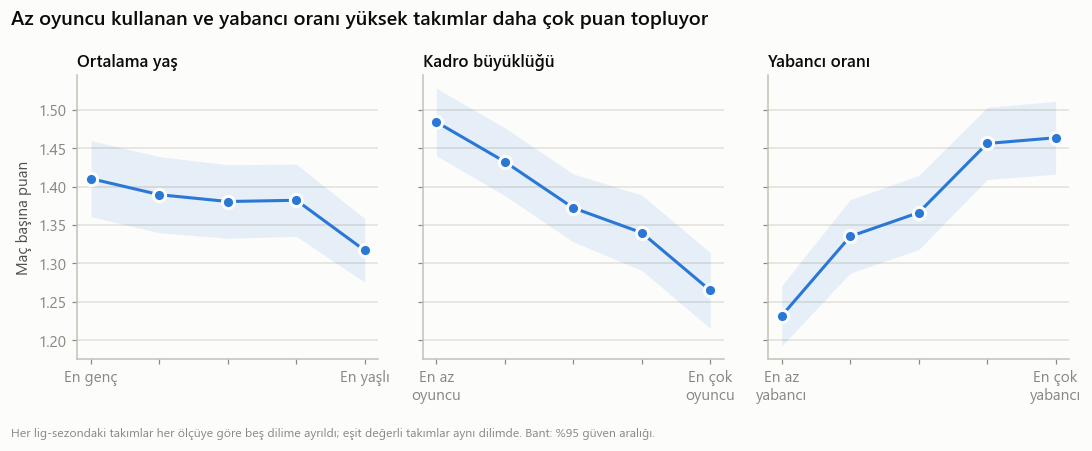

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8), sharey=True)
for ax, (metric, label, ends) in zip(axes, PANELS):
    stats = quintiles[label]
    ax.fill_between(stats.index, stats["ortalama"] - stats["ci"], stats["ortalama"] + stats["ci"],
                    color=BLUE, alpha=0.1, linewidth=0)
    ax.plot(stats.index, stats["ortalama"], color=BLUE, marker="o",
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.set_xticks([1, 2, 3, 4, 5], [ends[0], "", "", "", ends[1]])
    ax.grid(axis="x", visible=False)
    ax.set_title(label, fontsize=11)
axes[0].set_ylabel("Maç başına puan")
fig.suptitle("Az oyuncu kullanan ve yabancı oranı yüksek takımlar daha çok puan topluyor", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.text(0.01, -0.04, "Her lig-sezondaki takımlar her ölçüye göre beş dilime ayrıldı; eşit değerli takımlar aynı dilimde. Bant: %95 güven aralığı.",
         color=MUTED, fontsize=8)
fig.tight_layout()
save(fig, "q2_kadro_dilimler")
plt.show()

Eşitliklerin nasıl bozulduğu kadro büyüklüğünde önemli: satır sırası kullanılsaydı takımların %16'sı başka bir dilime düşecekti ve en az ile en çok oyuncu kullanan dilimler arasındaki fark 0,22 yerine 0,26 puan, yani yaklaşık %20 daha büyük görünecekti. Diğer iki ölçüde etki yok denecek kadar küçük.

Kadro büyüklüğünde en az oyuncu kullanan dilim maç başına 1,48 puan toplarken, en çok oyuncu kullanan dilim 1,26 puan topluyor. Yabancı oranında tablo tersine dönüyor: maç başına puan 1,23'ten 1,46'ya çıkıyor. Ortalama yaşta yalnızca en yaşlı dilimde hafif bir düşüş (1,32) görülüyor; ilk dört dilim birbirine çok yakın. 38 maçlık bir sezonda maç başına 0,22 puanlık fark, yaklaşık 8 puan demek.

### 2.3 Aynı takımın farklı sezonları

Aynı takım analizde birçok sezonla yer alıyor ve sezonları birbirine benziyor. Burada en yüksek ve en düşük dilim arasındaki farkın güven aralığı iki yolla hesaplanıyor: takım-sezonları bağımsız sayarak ve her takımın bütün sezonlarını tek bir küme sayarak.

In [16]:
rows = []
for metric, label, _ in PANELS:
    q = team[f"{metric}_q"]
    sums = team.assign(
        ppg_low=team["ppg"].where(q == 1, 0), n_low=q == 1,
        ppg_high=team["ppg"].where(q == 5, 0), n_high=q == 5,
    ).groupby(["league", "team_id"])[["ppg_low", "n_low", "ppg_high", "n_high"]].sum()
    diff = lambda t: t["ppg_high"] / t["n_high"] - t["ppg_low"] / t["n_low"]
    value = diff(sums.sum())
    stats = quintiles[label]
    naive_half = np.hypot(stats["ci"].iloc[0], stats["ci"].iloc[-1])  # iki bağımsız ortalamanın farkı
    low, high = cluster_bootstrap_ci(sums, diff)
    rows.append({"ölçü": label, "fark": value, "bağımsız_alt": value - naive_half,
                 "bağımsız_üst": value + naive_half, "küme_alt": low, "küme_üst": high})
pd.DataFrame(rows).set_index("ölçü").round(2)

,fark,bağımsız_alt,bağımsız_üst,küme_alt,küme_üst
ölçü,,,,,
Ortalama yaş,-0.09,-0.16,-0.03,-0.18,-0.01
Kadro büyüklüğü,-0.22,-0.29,-0.15,-0.30,-0.13
Yabancı oranı,0.23,0.17,0.29,0.14,0.33


Takım düzeyinde kümelenince aralıklar biraz genişliyor, ama kadro büyüklüğü ve yabancı oranındaki farkların aralıkları sıfırdan uzak kalıyor. Ortalama yaştaki fark ise küçük (−0,09) ve aralığın üst ucu sıfıra çok yakın (−0,01).

**Soru 2 için yanıt:** Kadronun ortalama yaşı ile başarı arasında ligler genelinde tutarlı bir ilişki bulunmadı. Yabancı oranı yüksek takımlar lig içinde daha çok puan topluyor (r = 0,19). Bunun bir nedeni, maddi gücü yüksek kulüplerin uluslararası transfer piyasasından daha çok oyuncu alabilmesi olabilir. Daha az oyuncu kullanan takımlar daha başarılı (r = −0,18), ama bu ilişkinin yönü belirsiz. İlişkilerin hepsi zayıf: her biri takımlar arasındaki puan farkının %4'ünden azını açıklıyor (r² < 0,04). Ayrıca ESPN'de veri eksikliği olan 222 takım-sezon bu analize alınmadı.

## Soru 3: Gol kralları ve takım başarısı

Gol kralı, bir lig-sezonda en çok gol atan oyuncu. Eşitlik varsa birden çok gol kralı oluyor. 99 lig-sezonun 91'inde ESPN'in listesi, 8'inde maç detaylarından sayılan goller kullanıldı (bkz. `01_cleaning.ipynb`).

In [17]:
top_keys = set(zip(top_scorers["league"], top_scorers["season"], top_scorers["team_id"]))
standings["has_top_scorer"] = [k in top_keys for k in zip(standings["league"], standings["season"], standings["team_id"])]
top_ranks = standings.loc[standings["has_top_scorer"], "rank"]
print(len(top_ranks), "gol kralı çıkaran takım-sezon")
print(f"şampiyon: %{(top_ranks == 1).mean() * 100:.0f} · ilk 4: %{(top_ranks <= 4).mean() * 100:.0f} · ortanca sıra: {top_ranks.median():.0f}")
top_ranks.value_counts().sort_index().rename("takım-sezon").to_frame().T

114 gol kralı çıkaran takım-sezon
şampiyon: %37 · ilk 4: %77 · ortanca sıra: 2


rank,1,2,3,4,5,6,7,8,9,10,11,13,14,17,19
takım-sezon,42,19,16,11,5,3,5,2,2,2,2,1,2,1,1


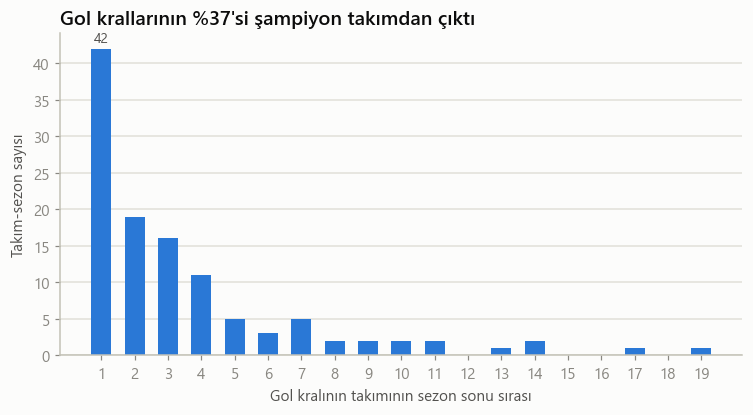

In [18]:
counts = top_ranks.value_counts().reindex(range(1, 25), fill_value=0)
counts = counts.loc[:counts[counts > 0].index.max()]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(counts.index, counts.values, width=0.6, color=BLUE)
ax.annotate(f"{counts.iloc[0]}", (1, counts.iloc[0]), xytext=(0, 4), textcoords="offset points",
            ha="center", color=INK_2, fontsize=9)
ax.set_xticks(counts.index)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Gol kralının takımının sezon sonu sırası")
ax.set_ylabel("Takım-sezon sayısı")
ax.set_title("Gol krallarının %37'si şampiyon takımdan çıktı")
save(fig, "q3_gol_krali_takim_sirasi")
plt.show()

Gol kralı çıkaran 114 takım-sezonun 42'si (%37) şampiyon olmuş, %77'si ilk dörtte bitirmiş. Ortanca sıra 2. Gol kralı çıkaran takımların büyük çoğunluğu ligin en güçlü takımları. Alt sıralardan çıkan gol kralları istisna; örneğin 17. ve 19. sırada biten takımlardan birer gol kralı çıkmış.

### 3.1 Aynı takım: gol kralı çıkardığı ve çıkarmadığı sezonlar

Gol kralları çoğunlukla zaten güçlü takımlardan çıkıyor. Bu yüzden asıl karşılaştırma, aynı takımın aynı ligdeki diğer sezonlarıyla yapılıyor. Takım o ligde olmadığı sezonlarda (örneğin küme düştüğünde) karşılaştırmaya girmiyor.

In [19]:
teams_with = standings.groupby(["league", "team_id"]).filter(lambda g: g["has_top_scorer"].any())
paired = teams_with.groupby(["league", "team_id", "has_top_scorer"])["rank"].mean().unstack().dropna()
paired.columns = ["çıkarmadığı sezonlar", "çıkardığı sezonlar"]
paired["fark"] = paired["çıkardığı sezonlar"] - paired["çıkarmadığı sezonlar"]
names = standings.drop_duplicates(["league", "team_id"], keep="last").set_index(["league", "team_id"])["team"]
paired["takım"] = [f"{names[k]} ({LEAGUE_NAMES[k[0]]})" for k in paired.index]

mean_diff, ci = mean_ci(paired["fark"])
print(len(paired), "takım")
print(f"ortalama sıra: gol kralı çıkardığı sezonlarda {paired['çıkardığı sezonlar'].mean():.1f}, "
      f"çıkarmadığı sezonlarda {paired['çıkarmadığı sezonlar'].mean():.1f}")
print(f"fark: {mean_diff:.1f} sıra (%95 GA {mean_diff - ci:.1f} ile {mean_diff + ci:.1f})")
print("daha iyi:", (paired["fark"] < 0).sum(), "· aynı:", (paired["fark"] == 0).sum(), "· daha kötü:", (paired["fark"] > 0).sum())

55 takım
ortalama sıra: gol kralı çıkardığı sezonlarda 4.9, çıkarmadığı sezonlarda 7.0
fark: -2.1 sıra (%95 GA -3.0 ile -1.3)
daha iyi: 41 · aynı: 0 · daha kötü: 14


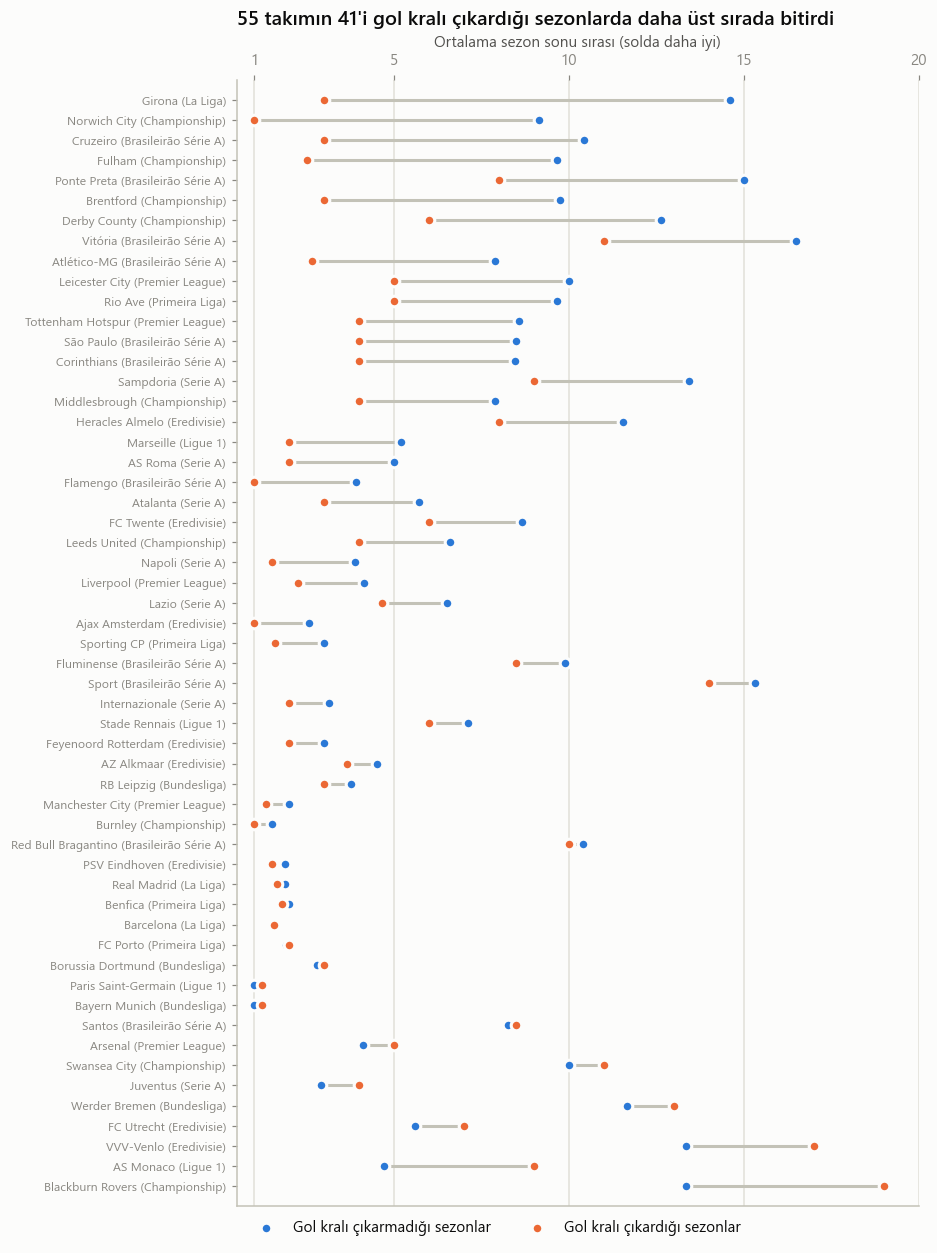

In [20]:
shown = paired.sort_values("fark", ascending=False)
fig, ax = plt.subplots(figsize=(8, 0.22 * len(shown) + 1.2))
ys = np.arange(len(shown))
ax.hlines(ys, shown["çıkardığı sezonlar"], shown["çıkarmadığı sezonlar"], color=AXIS, linewidth=2, zorder=1)
for col, color in [("çıkarmadığı sezonlar", BLUE), ("çıkardığı sezonlar", ORANGE)]:
    ax.scatter(shown[col], ys, s=48, color=color, edgecolor=SURFACE, linewidth=2, zorder=3,
               label=f"Gol kralı {col}")
ax.set_yticks(ys, shown["takım"], fontsize=8)
ax.set_ylim(-1, len(shown))
ax.grid(axis="y", visible=False)
ax.xaxis.set_ticks_position("top")
ax.xaxis.set_label_position("top")
ax.set_xlabel("Ortalama sezon sonu sırası (solda daha iyi)")
ax.set_xlim(0.5, None)
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_title("55 takımın 41'i gol kralı çıkardığı sezonlarda daha üst sırada bitirdi", pad=36)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0), ncols=2)
save(fig, "q3_ayni_takim_karsilastirma")
plt.show()

Gol kralı çıkaran 55 takımın ortalama sırası, gol kralı çıkardıkları sezonlarda 4,9, diğer sezonlarında 7,0. Ortalama fark 2,1 sıra (%95 güven aralığı 1,3–3,0). 41 takım gol kralı çıkardığı sezonlarda daha iyi, 14 takım daha kötü bitirmiş. Fark en çok normalde orta sıralarda biten takımlarda büyük; örneğin Girona ortalama 14,6. sıradan 3. sıraya çıkmış. Bayern ve PSG gibi neredeyse her sezon şampiyon olan takımlarda ise fark yok.

**Soru 3 için yanıt:** Evet. Gol kralı çıkaran takımlar o sezonlarda, aynı takımın diğer sezonlarına göre ortalama 2 sıra daha üstte bitiriyor. Ancak bu sonuç bir neden-sonuç ilişkisi kurmuyor. Takım iyi oynadığı için forvetine daha çok gol fırsatı yaratıyor olabilir; gol kralı da takımı yukarı taşıyor olabilir. Büyük olasılıkla ikisi birlikte etkili. Ayrıca 55 takımlık örneklem küçük ve 8 lig-sezonun gol kralı maç detaylarından hesaplandı.

## Bulguların özeti

| Soru | Bulgu | Dikkat edilecek nokta |
|---|---|---|
| 1. Ev sahibi avantajı | Seyircisiz maçlarda ev sahibi avantajı 0,46'dan 0,21'e, yarıdan fazla azaldı (%55); düşüş 9 ligin hepsinde görüldü. | Pandemide seyirci dışında başka koşullar da değiştiği için düşüşün tamamı seyirciye bağlanamaz. Az seyircili maçlarda avantajın normal seviyeye yaklaşması bir eğilim; güven aralıkları çok geniş. |
| 2. Kadro yapısı | Yabancı oranı yüksek (r = 0,19) ve daha az oyuncu kullanan (r = −0,18) takımlar daha çok puan topluyor. Yaşın tutarlı bir etkisi yok. | İlişkiler zayıf. Kadro büyüklüğünde ilişkinin yönü belirsiz. Veri eksikliği nedeniyle 222 takım-sezon analize alınmadı. |
| 3. Gol kralları | Gol kralı çıkaran takımlar o sezonlarda ortalama 2,1 sıra daha üstte bitiriyor; gol krallarının %37'si şampiyon takımdan çıkıyor. | Neden-sonuç ilişkisi kurulamıyor; örneklem 55 takım. |